In [1]:
from PIL import Image, ImageFilter
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.special import gamma as G
from scipy.stats import gamma,invgauss
from tifffile import imread

pi=np.pi

mat_full_image=np.load("sub_filtered4.npy") #sortie du filtre
plt.matshow(mat_full_image[4])

FileNotFoundError: [Errno 2] No such file or directory: 'sub_filtered4.npy'

Local maxima

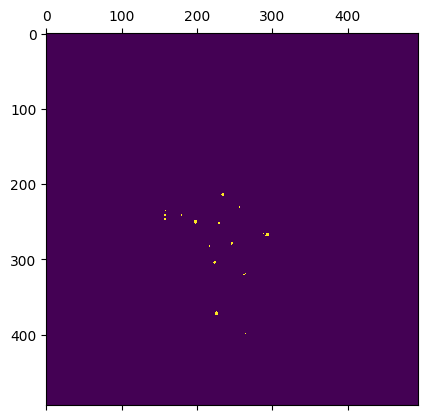

In [ ]:
mat=np.load("sub_thresholded4.npy")
plt.matshow(mat[0])

Local maxima

In [ ]:
test = np.array([[[False,0,0],
                [0,0,1],
                [0,True,1]],
                [[0,0,0],
                [0,1,0],
                [0,0,0]],
                [[0,0,0],
                [0,1,0],
                [0,0,0]]])

print(mat[:,:,1:])
coordinates = np.nonzero(test)
for i in range(len(coordinates[0])):
    print(coordinates[0][i])

[[[False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]
  ...
  [False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]]

 [[False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]
  ...
  [False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]]

 [[False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]
  ...
  [False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]]

 ...

 [[False False False ... False False False]
  [False False False ... False False False]
  [False False False ... False False False]
  ...
  [False False False ... False False Fal

In [ ]:
#init

coordinates = np.nonzero(mat[:,:,1:])
values = mat_full_image[coordinates[0],coordinates[1],coordinates[2]]
permutation = np.argsort(values)[::-1]
coordinates_sorted = coordinates[0][permutation],coordinates[1][permutation],coordinates[2][permutation]
values_sorted = values[permutation]
# print(np.max(values),values_sorted)
is_local_max=np.full(len(coordinates[0]),0)

print(coordinates_sorted)


(array([135, 135, 136, ...,  31,  31,  39], shape=(63179,)), array([237, 238, 237, ..., 430, 431, 431], shape=(63179,)), array([202, 202, 202, ...,  45,  45,  45], shape=(63179,)))


In [ ]:
sigma = sigma=(1/2.3548)*2.7
l,m,n = 50,250,250

d = np.sqrt((coordinates_sorted[0]-m)**2 + (coordinates_sorted[1]-n)**2 + (coordinates_sorted[0]-l)**2)

roi = (0 < d) & (d < 100*sigma)

neighbor_coord = coordinates_sorted[0][roi],coordinates_sorted[1][roi],coordinates_sorted[2][roi]

print(neighbor_coord)

test = mat_full_image[l][m][n] > mat_full_image[neighbor_coord]
local_max_test = np.all(test)

i=111

if is_local_max[i] == 0 :
    is_local_max[roi] = np.where(test,-1,is_local_max[roi])

print(local_max_test)
print(is_local_max[roi])
print(test)
is_local_max[roi] = np.where(test,-1,is_local_max[roi])
print(is_local_max[roi])





(array([], dtype=int64), array([], dtype=int64), array([], dtype=int64))
True
[]
[]
[]


In [ ]:
i=50
is_local_max=np.full(len(coordinates[0]),0)
if is_local_max[i] == 0 :
    # coordinates and distance
    l,m,n = coordinates_sorted[0][i],coordinates_sorted[1][i],coordinates_sorted[2][i]
    d = np.sqrt((coordinates_sorted[1]-m)**2 + (coordinates_sorted[2]-n)**2 + (coordinates_sorted[0]-l)**2)

    # neighborhood mask
    roi = (0 < d) & (d < 3*sigma)
    neighbor_coord = coordinates_sorted[0][roi],coordinates_sorted[1][roi],coordinates_sorted[2][roi]

    test = mat_full_image[l][m][n] > mat_full_image[neighbor_coord]
    local_max_test = np.all(test)

    is_local_max[roi] = np.where(test,-1,is_local_max[roi])
    if local_max_test == True :
        is_local_max[i] = 1
    else :
        is_local_max[i] = -1

else :
    is_local_max[i] = -1

print(is_local_max[i])
print(is_local_max[roi])
    

-1
[ 0  0  0  0  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


[ 1 -1 -1 ... -1 -1 -1]
[ True False False ... False False False]
(array([135, 138,  33, ..., 277,  65,  15], shape=(1066,)), array([237, 238, 270, ..., 387, 347, 352], shape=(1066,)), array([202, 208, 136, ...,  42,  92, 138], shape=(1066,)))


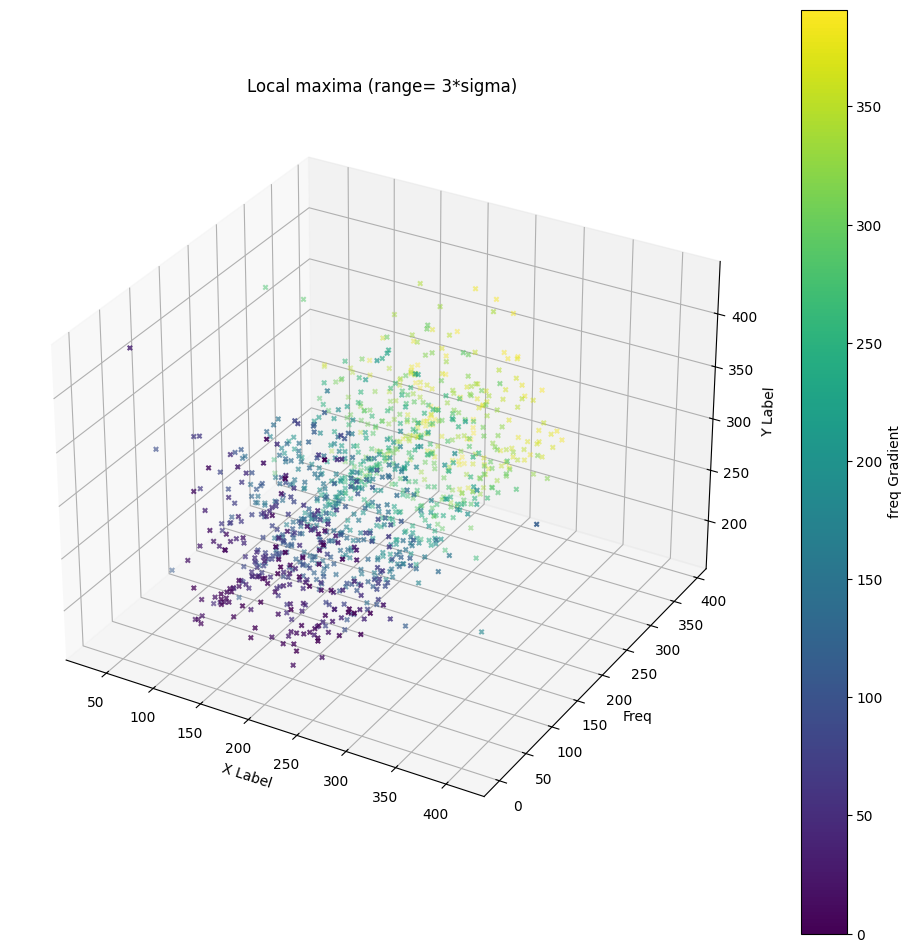

In [ ]:
l = len(coordinates[0])
for i in range(l):
    if is_local_max[i] == 0 :
        # coordinates and distance
        l,m,n = coordinates_sorted[0][i],coordinates_sorted[1][i],coordinates_sorted[2][i]
        d = np.sqrt((coordinates_sorted[0]-l)**2 + (coordinates_sorted[1]-m)**2 + (coordinates_sorted[2]-n)**2)

        # neighborhood mask
        roi = (0 < d) & (d < 3*sigma)
        neighbor_coord = coordinates_sorted[0][roi],coordinates_sorted[1][roi],coordinates_sorted[2][roi]

        test = mat_full_image[l][m][n] > mat_full_image[neighbor_coord]
        local_max_test = np.all(test)

        is_local_max[roi] = np.where(test,-1,is_local_max[roi])
        if local_max_test == True :
            is_local_max[i] = 1
        else :
            is_local_max[i] = -1

else :
    is_local_max[i] = -1

print(is_local_max)
local_max_mask = is_local_max == 1
print(local_max_mask)

local_max_coordinates = coordinates_sorted[0][local_max_mask],coordinates_sorted[1][local_max_mask],coordinates_sorted[2][local_max_mask]

print(local_max_coordinates)

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

# plt.matshow(mat_full_image[0], interpolation='none', cmap='viridis', vmax=np.quantile(mat_full_image, 0.999))
# plt.matshow(mat)
scatter=ax.scatter(local_max_coordinates[2],local_max_coordinates[0], local_max_coordinates[1],c=local_max_coordinates[0],marker='x', cmap='viridis',s=10)
plt.title("Local maxima (range= 3*sigma)")
colorbar = plt.colorbar(scatter)
colorbar.set_label('freq Gradient')
ax.set_xlabel('X Label')
ax.set_ylabel('Freq')
ax.set_zlabel('Y Label')
plt.show()

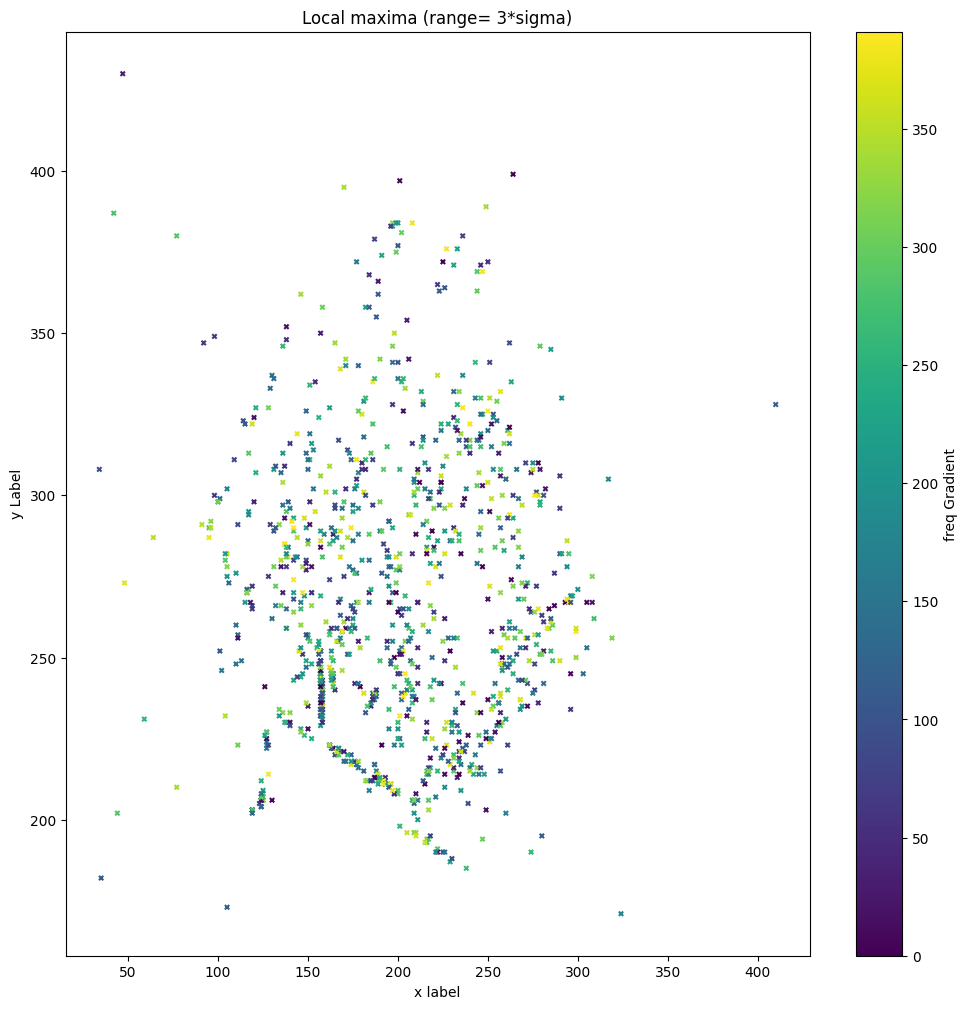

In [ ]:
plt.figure(figsize=(12, 12))
scatter=plt.scatter(local_max_coordinates[2], local_max_coordinates[1],c=local_max_coordinates[0],marker='x', cmap='viridis',s=10)
plt.title("Local maxima (range= 3*sigma)")
colorbar = plt.colorbar(scatter)
colorbar.set_label('freq Gradient')
plt.xlabel('x label')
plt.ylabel('y Label')
plt.show()

correctness

In [ ]:
local_max_coordinates[0]
permutation2 = np.argsort(local_max_coordinates[0])[::]
local_max_coordinates_sorted = local_max_coordinates[0][permutation2],local_max_coordinates[1][permutation2],local_max_coordinates[2][permutation2]

print(local_max_coordinates_sorted[0])

[  0   0   0 ... 390 391 391]


In [ ]:
for a in range(40):
    print(local_max_coordinates_sorted[0][a],local_max_coordinates_sorted[1][a],local_max_coordinates_sorted[2][a])

#check le problème de doublons 

0 252 229
0 304 224
0 246 157
0 236 157
0 266 287
0 282 216
0 372 225
0 230 256
0 214 234
0 213 187
0 241 179
0 289 219
0 250 198
0 267 293
0 241 157
1 223 191
1 399 264
1 321 262
2 278 247
4 304 212
4 241 126
5 282 235
6 236 236
6 270 199
6 310 278
6 245 296
7 239 158
7 265 284
7 267 305
8 284 157
8 299 237
8 246 163
8 206 130
8 259 171
9 264 200
9 267 195
9 222 164
9 211 215
9 214 226
10 250 258


1606.2685952808272


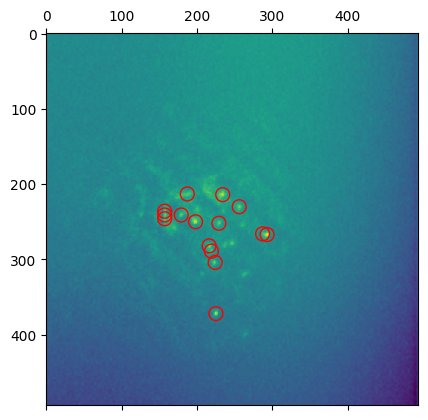

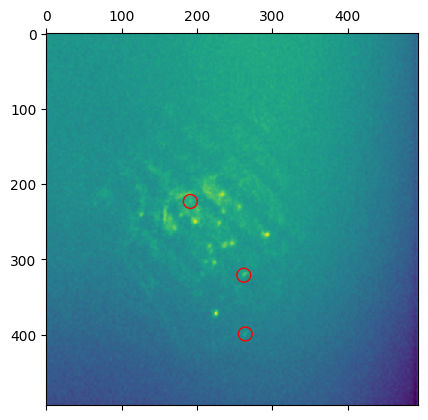

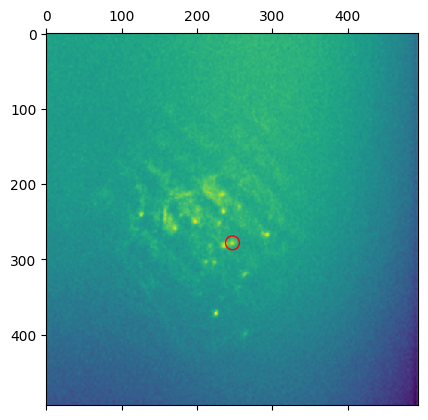

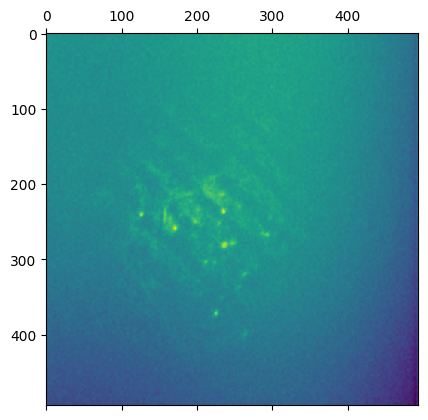

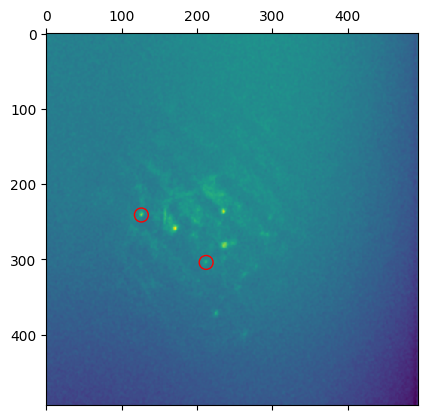

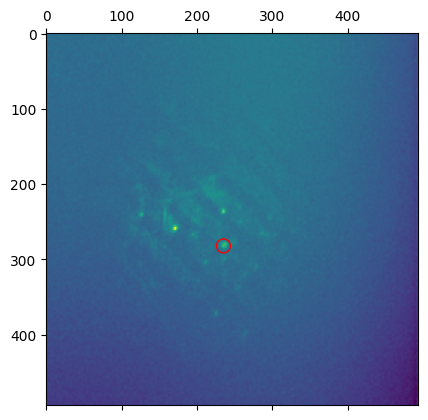

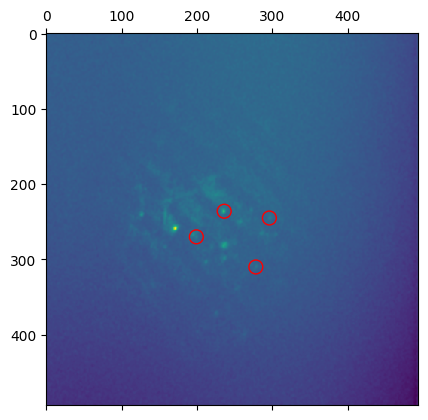

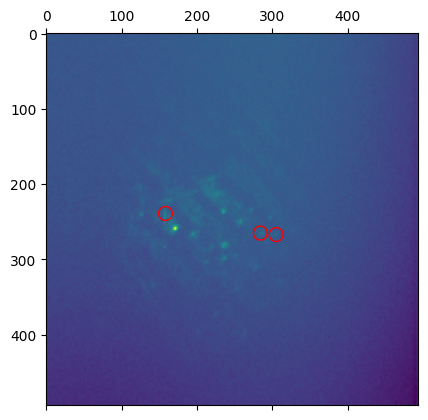

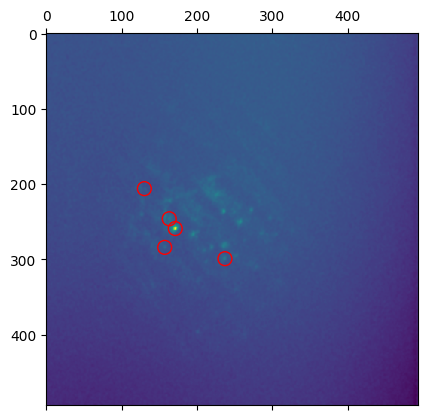

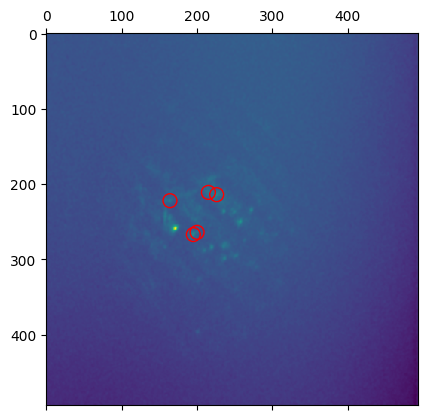

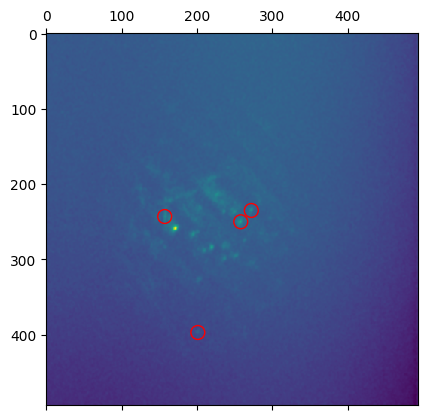

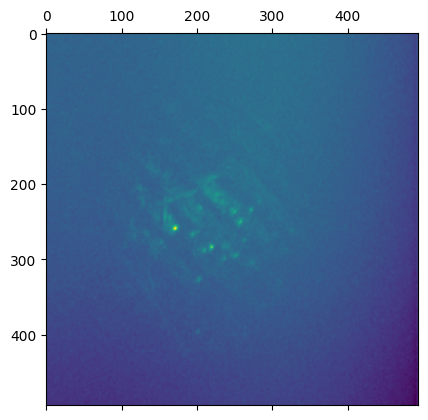

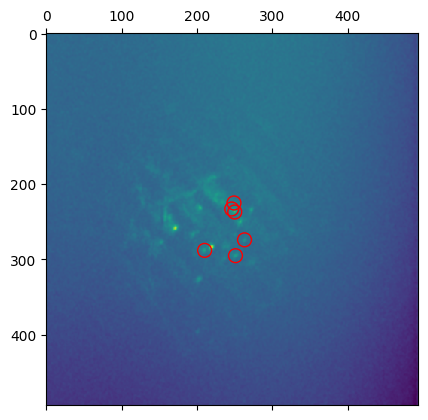

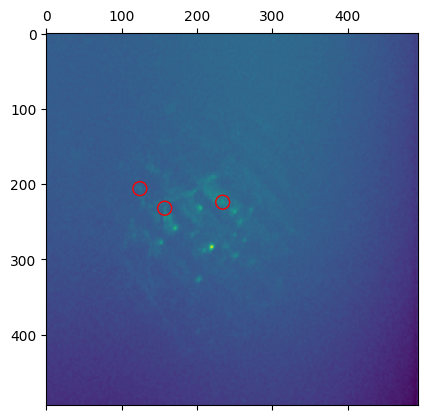

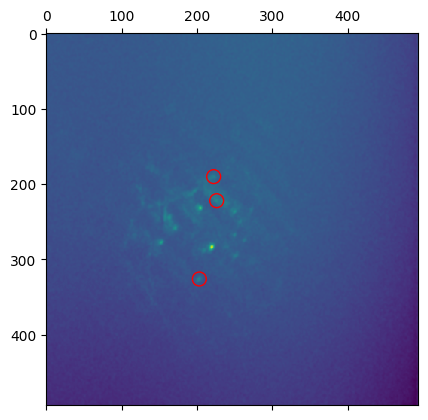

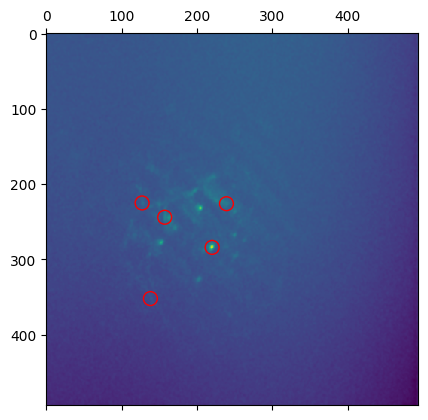

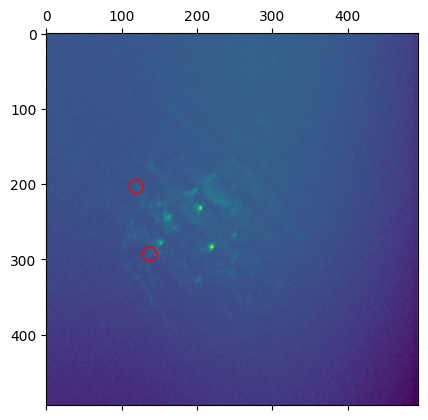

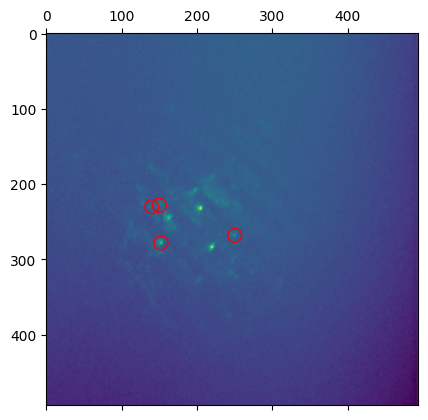

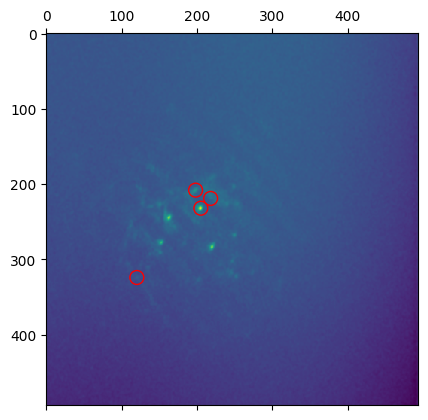

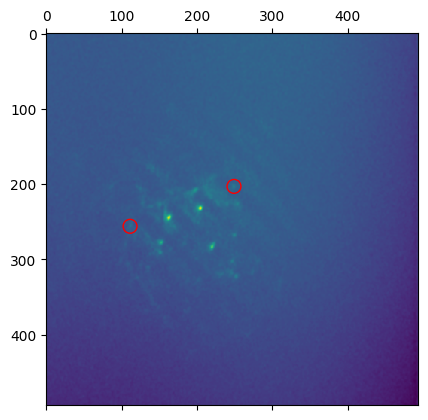

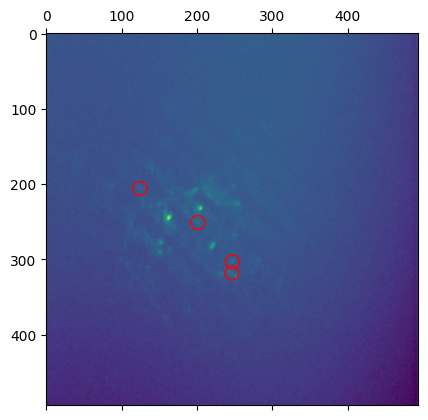

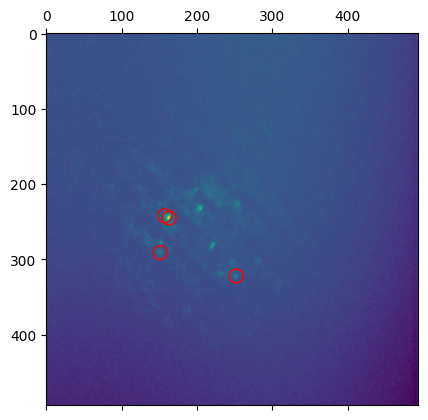

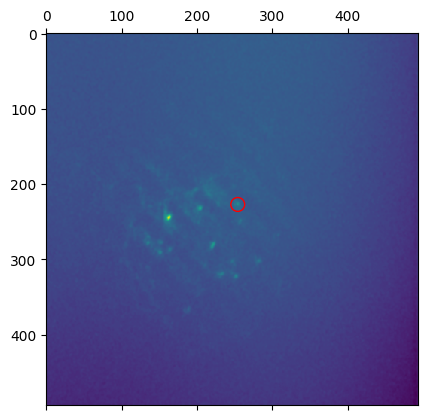

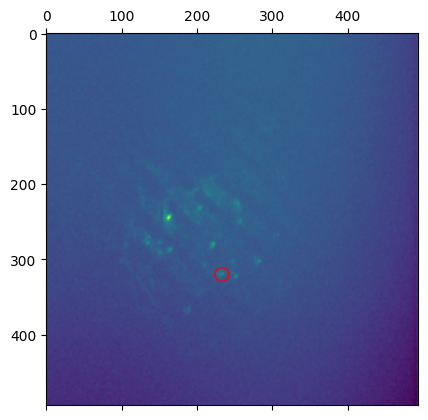

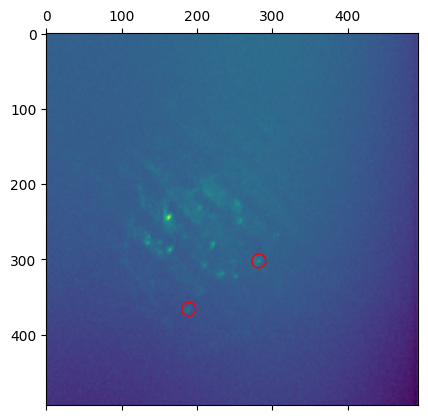

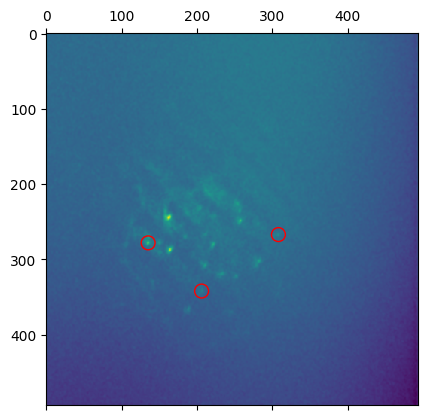

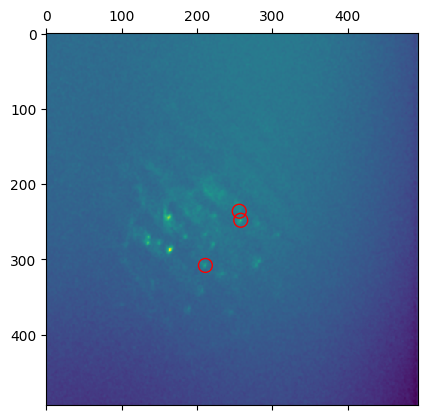

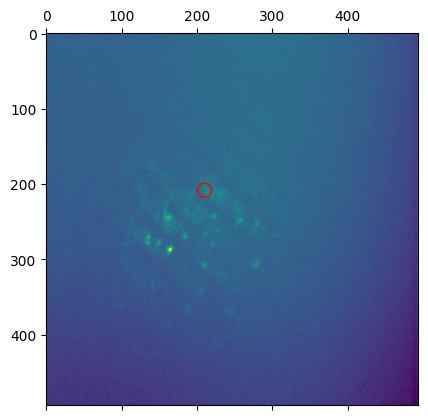

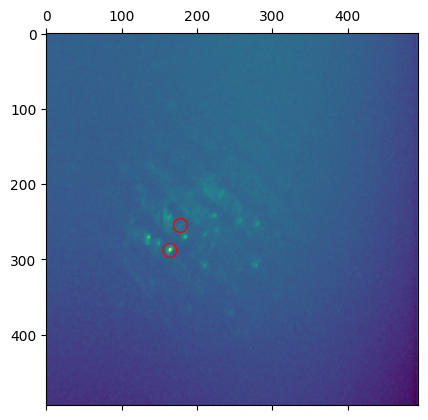

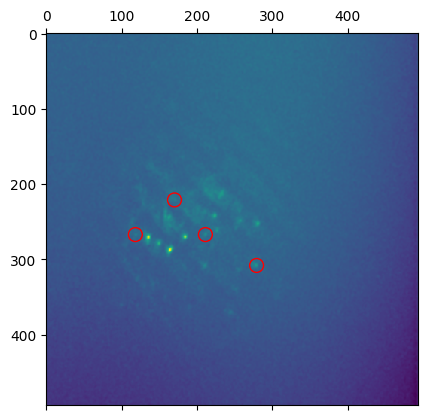

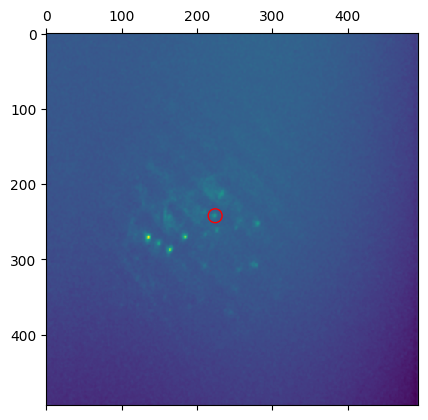

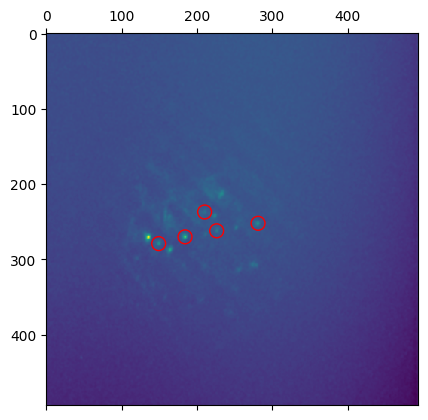

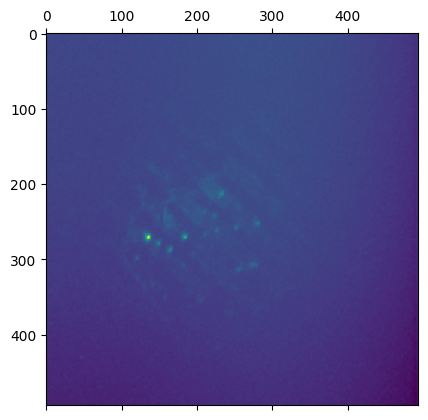

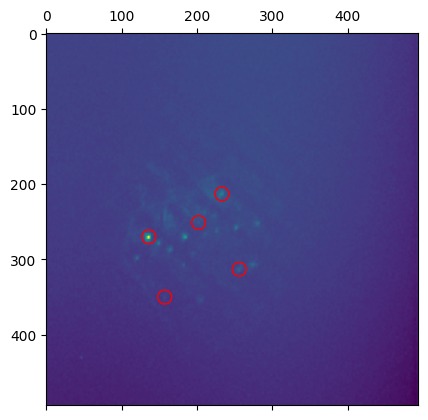

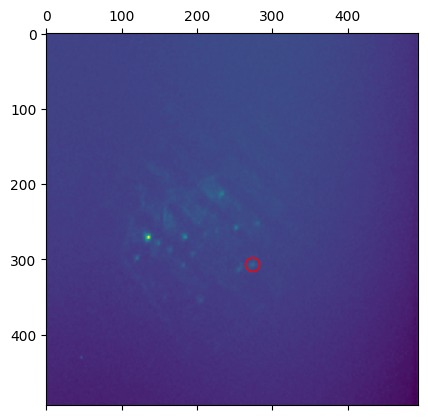

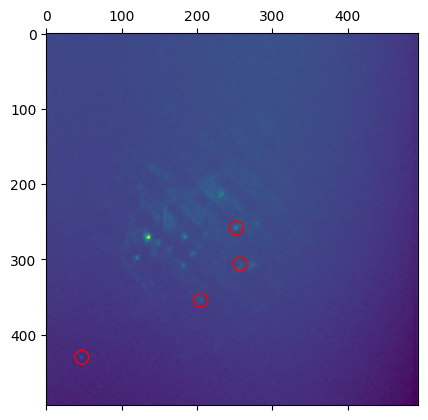

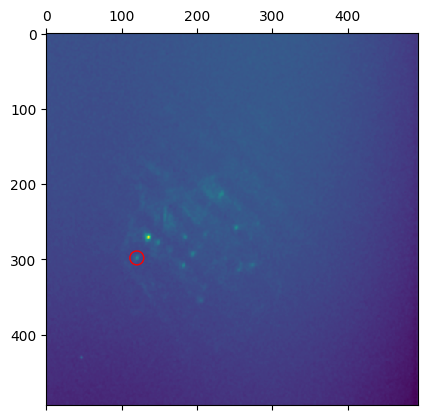

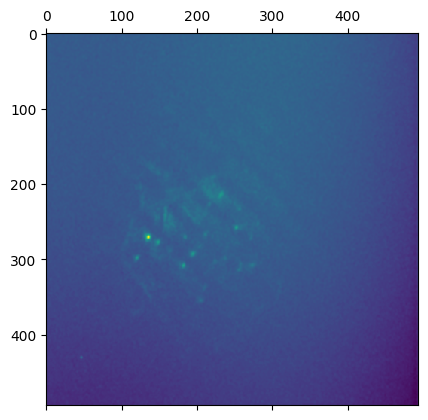

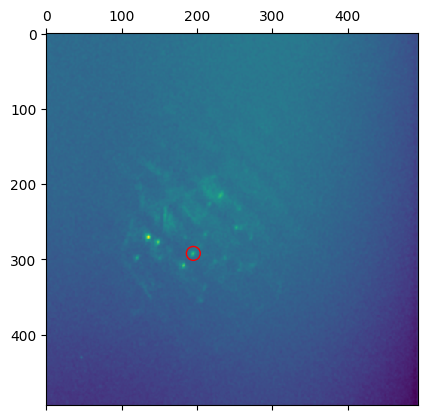

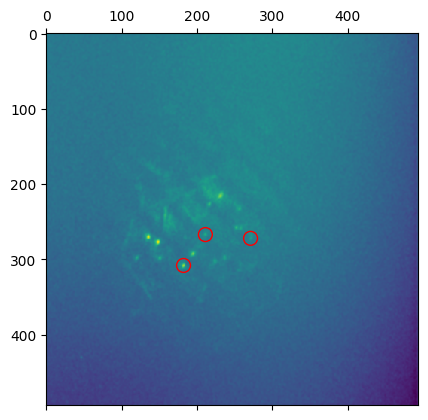

In [ ]:
start=0
end=40
c=0
print(np.mean(mat_full_image[0]))
for i in range(start,end):
    plt.matshow(mat_full_image[i])
    while i == local_max_coordinates_sorted[0][c]:
        plt.scatter(local_max_coordinates_sorted[2][c],local_max_coordinates_sorted[1][c], s=100, facecolors='none', edgecolors='r', lw=1)
        c=c+1
    plt.show()